# Cat vs Dog Image Prediction

This notebook loads the trained InceptionV3 model and uses it to classify a new image as either a cat or a dog.

### Workflow

1. Load the trained model
2. Load and preprocess an image
3. Make a prediction
4. Display the result

In [3]:
import cv2 as cv
import numpy as np
import matplotlib.pyplot as plt

from keras.models import load_model
from keras.applications.inception_v3 import preprocess_input


MODEL_PATH = "models/cat_dog_inceptionv3.keras"
IMAGE_PATH = "images/dog.jpg"

IMAGE_SIZE = (299, 299)
DOG_THRESHOLD = 0.7

## 1. Load the Trained Model and Image

We load the model trained in the previous notebook.

We then load the image that we want to classify.

In [4]:
# Load the trained model

model = load_model(MODEL_PATH)


# Load the image

image = cv.imread(IMAGE_PATH)

if image is None:
    raise FileNotFoundError(
        f"Could not find the image: {IMAGE_PATH}"
    )

original_image = image.copy()

print("Model and image loaded successfully.")

Model and image loaded successfully.


## 2. Preprocess the Image

InceptionV3 expects an image with a size of `299 × 299`.

We convert the image from BGR to RGB, resize it, apply the InceptionV3 preprocessing function, and add a batch dimension.

In [5]:
image = cv.cvtColor(image, cv.COLOR_BGR2RGB)
image = cv.resize(image, IMAGE_SIZE)

image = preprocess_input(image)

image = np.expand_dims(image, axis=0)

## 3. Make the Prediction

The model outputs a probability between 0 and 1.

We use `0.7` as the decision threshold:

- Probability ≥ 0.7 → Dog
- Probability < 0.7 → Cat

In [6]:
prediction = model.predict(image, verbose=0)

dog_probability = prediction[0][0]
cat_probability = 1 - dog_probability


if dog_probability >= DOG_THRESHOLD:
    predicted_class = "Dog"
    confidence = dog_probability
else:
    predicted_class = "Cat"
    confidence = cat_probability


print(f"Prediction: {predicted_class}")
print(f"Confidence: {confidence:.2%}")

Prediction: Dog
Confidence: 99.97%


## 4. Display the Result

Finally, we display the original image together with the model's prediction and confidence.

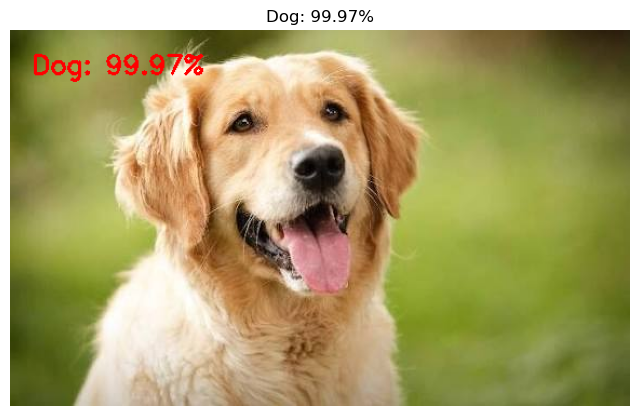

In [7]:
message = f"{predicted_class}: {confidence:.2%}"

cv.putText(
    original_image,
    message,
    (20, 40),
    cv.FONT_HERSHEY_SIMPLEX,
    0.8,
    (0, 0, 255),
    2
)

plt.figure(figsize=(8, 6))

plt.imshow(cv.cvtColor(original_image, cv.COLOR_BGR2RGB))
plt.title(message)
plt.axis("off")
plt.show()